# Colab training
Scaffold only: no training cells are implemented.

1. TODO: mount Drive, obtain repository and validate dependencies.
2. TODO: resolve config settings; audit and group Kvasir-SEG before freezing splits.
3. TODO: run synthetic CPU checks, then a timed GPU pilot.
4. TODO: train A and B with identical initialization, data order and settings.
5. TODO: select checkpoints and thresholds on validation; persist artifacts.
6. TODO: run the single final evaluation script for both models only when frozen.


# Importing data and defining datasets and loaders

In [99]:
import os
from pathlib import Path
import torch
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms
from torchvision.io import decode_image

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [127]:
class Kvasir(Dataset):
    def __init__(self, image_dir, mask_dir, input_transform=None, target_transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.input_transform = input_transform
        self.target_transform = target_transform
        self.images_path = []
        self.masks_path = []


        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        for image_path in self.image_dir.iterdir():
            mask_path = os.path.join(self.mask_dir, image_path.name)
            if not os.path.exists(mask_path):
                raise ValueError(f"Mask file {mask_path} does not exist for image {image_path}")
            self.images_path.append(image_path)
            self.masks_path.append(mask_path)


    def __len__(self):
        return len(self.images_path)

    def __getitem__(self, idx):
        image_path = self.images_path[idx]
        mask_path = self.masks_path[idx]

        # Decode RGB pixels as float32 in [0, 1] for the model.
        image = decode_image(str(image_path), mode="RGB").float() / 255.0
        # Binary foreground target: one float32 channel, values {0, 1}.
        mask = (decode_image(str(mask_path), mode="GRAY") > 127).float()

        if self.input_transform:
            image = self.input_transform(image)
        if self.target_transform:
            mask = self.target_transform(mask)

        return image, mask


In [149]:
# Edit these values before running the notebook.
DATA_DIR = Path(r"C:/Users/issak/Desktop/SIVO/Projet Indiv/UNet-Polyp-segmentation/data/Kvasir-SEG")
IMAGE_DIR = DATA_DIR / "images"
MASK_DIR = DATA_DIR / "masks"
IMAGE_SIZE = (256, 256)
BATCH_SIZE = 8
SEED = 42

initial_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
])


mask_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE, interpolation=transforms.InterpolationMode.NEAREST),
])

kvasir_dataset = Kvasir(
    image_dir=IMAGE_DIR,
    mask_dir=MASK_DIR,
    input_transform=initial_transform,
    target_transform=mask_transform
)

train_dataset, val_dataset, test_dataset = random_split(
    kvasir_dataset,
    [700, 150, 150],
    generator=torch.Generator().manual_seed(SEED),
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=1, shuffle=False
)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000001].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000002].


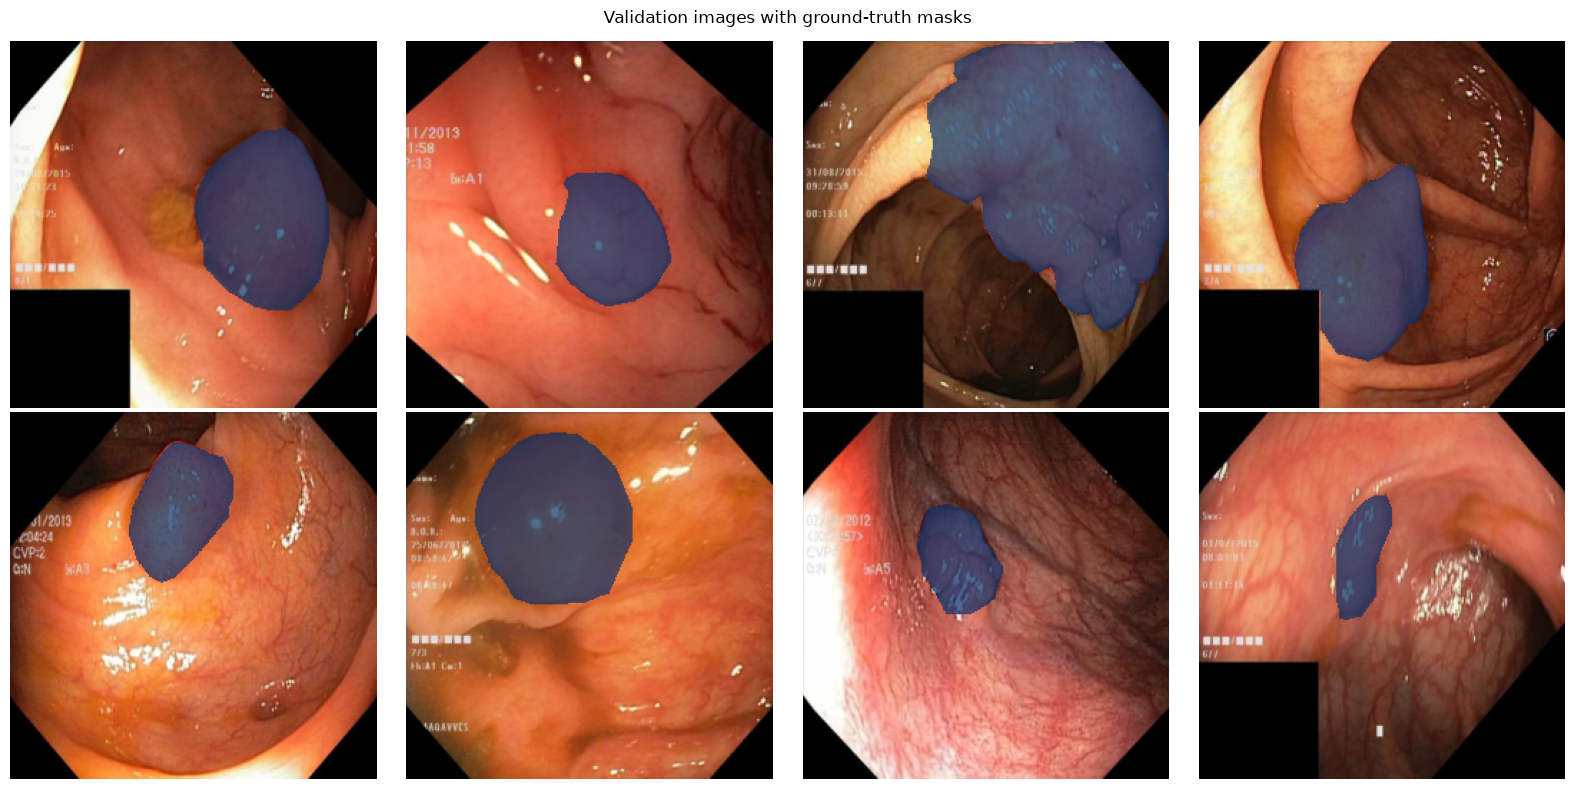

In [150]:
import numpy as np
import matplotlib.pyplot as plt

samples = []
for images, masks in val_loader:
    for image, mask in zip(images, masks):
        samples.append((image.cpu(), mask.cpu()))
        if len(samples) == 8:
            break
    if len(samples) == 8:
        break

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (image, mask) in zip(axes.flat, samples):
    image = image.permute(1, 2, 0).numpy()  # CHW → HWC
    mask = mask.squeeze(0).numpy()         # 1HW → HW

    ax.imshow(image)
    ax.imshow(
        np.ma.masked_where(mask < 0.5, mask),
        cmap="Blues",
        vmin=0,
        vmax=1,
        alpha=0.7,
    )

for ax in axes.flat:
    ax.axis("off")

fig.suptitle("Validation images with ground-truth masks")
plt.tight_layout()
plt.show()

# Model

In [151]:
import torch
from torch import nn
from torch.nn import functional as F


class DoubleConv(nn.Module):
  def __init__(self, iin_channels, out_channels):
    super(DoubleConv, self).__init__()

    self.conv = nn.Sequential(
        nn.Conv2d(iin_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )

  def forward(self, x):
    return self.conv(x)



class Down(nn.Module):
  def __init__(self, iin_channels, out_channels):
    super(Down, self).__init__()

    self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)
    self.conv = DoubleConv(iin_channels, out_channels)

  def forward(self, x):
    x = self.maxpool(x)
    x = self.conv(x)
    return x

class Up(nn.Module):
  def __init__(self, iin_channels, skip_channels, out_channels):
    super(Up, self).__init__()

    # Upsample the decoder feature map, then concatenate the matching encoder feature map.
    self.up = nn.ConvTranspose2d(iin_channels, iin_channels // 2, kernel_size=2, stride=2)
    self.conv = DoubleConv(iin_channels // 2 + skip_channels, out_channels)

  def forward(self, x1, x2):
    x1 = self.up(x1)
    # Handle odd input dimensions without changing the mask interpolation policy.
    diff_y = x2.size(2) - x1.size(2)
    diff_x = x2.size(3) - x1.size(3)
    x1 = F.pad(x1, [diff_x // 2, diff_x - diff_x // 2,
                    diff_y // 2, diff_y - diff_y // 2])
    x = torch.cat([x2, x1], dim=1)
    return self.conv(x)



class Encoder(nn.Module):
  def __init__(self, in_channels, channels):
    super(Encoder, self).__init__()
    # Example: channels = [64, 128, 256]
    self.inp = DoubleConv(in_channels, channels[0])
    self.down1 = Down(channels[0], channels[1])
    self.down2 = Down(channels[1], channels[2])

  def forward(self, x):
    x1 = self.inp(x)
    x2 = self.down1(x1)
    x3 = self.down2(x2)
    return x1, x2, x3

class Decoder(nn.Module):
  def __init__(self, in_channels, channels):
    super(Decoder, self).__init__()
    self.up1 = Up(channels[2], channels[1], channels[1])
    self.up2 = Up(channels[1], channels[0], channels[0])
    self.out = nn.Conv2d(channels[0], in_channels, kernel_size=1)

  def forward(self, x1, x2, x3):
    x = self.up1(x3, x2)
    x = self.up2(x, x1)
    x = self.out(x)
    return x


class UNet(nn.Module):
  def __init__(self, in_channels, channels):
    super(UNet, self).__init__()

    self.encoder = Encoder(in_channels, channels)
    self.decoder = Decoder(1, channels)

  def forward(self, x):
    x1, x2, x3 = self.encoder(x)
    x = self.decoder(x1, x2, x3)
    return x

# Training

In [152]:
import random
import time

OUTPUT_DIR = Path("results")
REPORTING_INTERVAL = 10
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def train_model(model, lr, loss_fn, epochs, train_loader, val_loader, device):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = loss_fn
    history = []
    assert len(train_loader) > 0 and len(val_loader) > 0, "Loaders must not be empty"

    last_loss = None

    for epoch in range(epochs):
        epoch_start = time.perf_counter()
        model.train()
        running_loss = 0.0
        for batch_idx, (image, mask) in enumerate(train_loader):
            image, mask = image.to(device), mask.to(device)
            optimizer.zero_grad()
            outputs = model(image)
            assert outputs.shape == mask.shape, "Expected matching [B, 1, H, W] tensors"
            loss = criterion(outputs, mask)
            loss.backward()
            optimizer.step()

            # Weight batch means by sample count, including the last partial batch.
            running_loss += loss.item()
            if batch_idx % REPORTING_INTERVAL == 0:
                last_loss = running_loss / REPORTING_INTERVAL
                print(f"Epoch {epoch + 1}/{epochs} | "
                    f"Batch {batch_idx + 1}/{len(train_loader)} | "
                    f"Running train loss: {running_loss / REPORTING_INTERVAL:.4f}")
                running_loss = 0.0

        model.eval()
        val_loss = 0.0
        val_samples = 0
        with torch.no_grad():
            for val_image, val_mask in val_loader:
                val_image, val_mask = val_image.to(device), val_mask.to(device)
                val_outputs = model(val_image)
                val_loss += criterion(val_outputs, val_mask).item() * val_image.size(0)
                val_samples += val_image.size(0)
        avg_val_loss = val_loss / val_samples
        history.append({"epoch": epoch + 1, "train_loss": last_loss,
                        "val_loss": avg_val_loss,
                        "learning_rate": optimizer.param_groups[0]["lr"],
                        "seconds": time.perf_counter() - epoch_start})

        print(f"Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {last_loss:.4f} | Val loss: {avg_val_loss:.4f}")

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot([row["epoch"] for row in history],
            [row["train_loss"] for row in history], marker="o", label="Train")
    ax.plot([row["epoch"] for row in history],
            [row["val_loss"] for row in history], marker="o", label="Validation")
    ax.set(xlabel="Epoch", ylabel="BCE loss", title="Training and validation loss")
    ax.set_xticks([row["epoch"] for row in history])
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "loss_curves.png", dpi=150)
    plt.show()
    plt.close(fig)
    print(f"Loss curve saved to: {(OUTPUT_DIR / 'loss_curves.png').resolve()}")


In [153]:
def dice_loss(output, target):
    intersection = (output * target).sum(dim=(1, 2, 3))
    dice = (2.0 * intersection) / (output.sum(dim=(1, 2,3)) + target.sum(dim=(1, 2, 3)) + 1e-8)  # Added epsilon to avoid division by zero
    return 1.0 - dice.mean()

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


CHANNELS = [8, 16, 32]
EPOCHS = 20
LEARNING_RATE = 0.001

In [155]:
unet = UNet(in_channels=3, channels=CHANNELS).to(device)
bce_loss = nn.BCEWithLogitsLoss()
train_model(unet, lr=LEARNING_RATE, loss_fn=bce_loss, epochs=EPOCHS, train_loader=train_loader, val_loader=val_loader, device=device)

Epoch 1/20 | Batch 1/88 | Running train loss: 0.0697
Epoch 1/20 | Batch 11/88 | Running train loss: 0.6420
Epoch 1/20 | Batch 21/88 | Running train loss: 0.6022
Epoch 1/20 | Batch 31/88 | Running train loss: 0.5728
Epoch 1/20 | Batch 41/88 | Running train loss: 0.5533
Epoch 1/20 | Batch 51/88 | Running train loss: 0.5279
Epoch 1/20 | Batch 61/88 | Running train loss: 0.5164
Epoch 1/20 | Batch 71/88 | Running train loss: 0.5106
Epoch 1/20 | Batch 81/88 | Running train loss: 0.5134
Epoch 1/20 | Train loss: 0.5134 | Val loss: 0.4874
Epoch 2/20 | Batch 1/88 | Running train loss: 0.0488
Epoch 2/20 | Batch 11/88 | Running train loss: 0.4965
Epoch 2/20 | Batch 21/88 | Running train loss: 0.4785
Epoch 2/20 | Batch 31/88 | Running train loss: 0.4828
Epoch 2/20 | Batch 41/88 | Running train loss: 0.4734
Epoch 2/20 | Batch 51/88 | Running train loss: 0.4572
Epoch 2/20 | Batch 61/88 | Running train loss: 0.4707
Epoch 2/20 | Batch 71/88 | Running train loss: 0.4461
Epoch 2/20 | Batch 81/88 | Runnin

KeyboardInterrupt: 

Epoch 1/5 | Batch 1/88 | Running train loss: 0.1960
Epoch 1/5 | Batch 11/88 | Running train loss: 1.1795
Epoch 1/5 | Batch 21/88 | Running train loss: 1.0737
Epoch 1/5 | Batch 31/88 | Running train loss: 1.0187
Epoch 1/5 | Batch 41/88 | Running train loss: 0.9553
Epoch 1/5 | Batch 51/88 | Running train loss: 0.9010
Epoch 1/5 | Batch 61/88 | Running train loss: 0.8419
Epoch 1/5 | Batch 71/88 | Running train loss: 0.7681
Epoch 1/5 | Batch 81/88 | Running train loss: 0.7215
Epoch 1/5 | Train loss: 0.7215 | Val loss: 0.7955
Epoch 2/5 | Batch 1/88 | Running train loss: -0.3342
Epoch 2/5 | Batch 11/88 | Running train loss: 0.9456
Epoch 2/5 | Batch 21/88 | Running train loss: 0.9327
Epoch 2/5 | Batch 31/88 | Running train loss: 0.9158
Epoch 2/5 | Batch 41/88 | Running train loss: 0.9895
Epoch 2/5 | Batch 51/88 | Running train loss: 1.0143
Epoch 2/5 | Batch 61/88 | Running train loss: 1.0090
Epoch 2/5 | Batch 71/88 | Running train loss: 1.0373
Epoch 2/5 | Batch 81/88 | Running train loss: 1.01

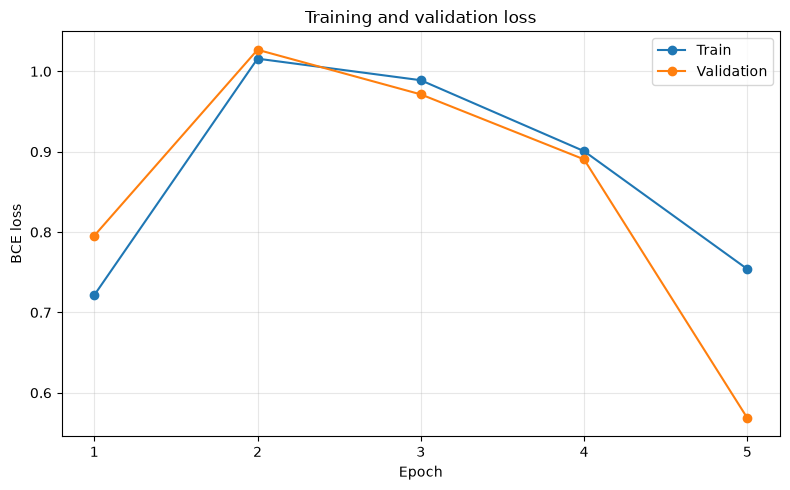

Loss curve saved to: C:\Users\issak\Desktop\SIVO\Projet Indiv\UNet-Polyp-segmentation\notebooks\results\loss_curves.png


In [ ]:
unet2 = UNet(in_channels=3, channels=CHANNELS)
dice_loss_fn = dice_loss
train_model(unet2, lr=LEARNING_RATE, loss_fn=dice_loss_fn, epochs=EPOCHS, train_loader=train_loader, val_loader=val_loader, device=device)

In [161]:
from torchmetrics import JaccardIndex, F1Score, Precision, Recall

iou = JaccardIndex(task='binary')
dice = F1Score(task='binary')
precision = Precision(task='binary')
Recall = Recall(task='binary')

In [166]:
def evaluate_model(model, test_loader, device):
    model.to(device)
    model.eval()
    scores = {"iou": [], "dice": [], "precision": [], "recall": []}
    for images, masks in test_loader:
        images, masks = images.to(device), masks.to(device)
        with torch.no_grad():
            outputs = model(images)
            preds = torch.sigmoid(outputs) > 0.5  # Convert logits to binary predictions

            iou_score = iou(preds, masks.int())
            dice_score = dice(preds, masks.int())
            precision_score = precision(preds, masks.int())
            recall_score = Recall(preds, masks.int())

            scores["iou"].append(iou_score.item())
            scores["dice"].append(dice_score.item())
            scores["precision"].append(precision_score.item())
            scores["recall"].append(recall_score.item())

    return {k: np.mean(v) if v else 0 for k, v in scores.items()}  # Return average scores

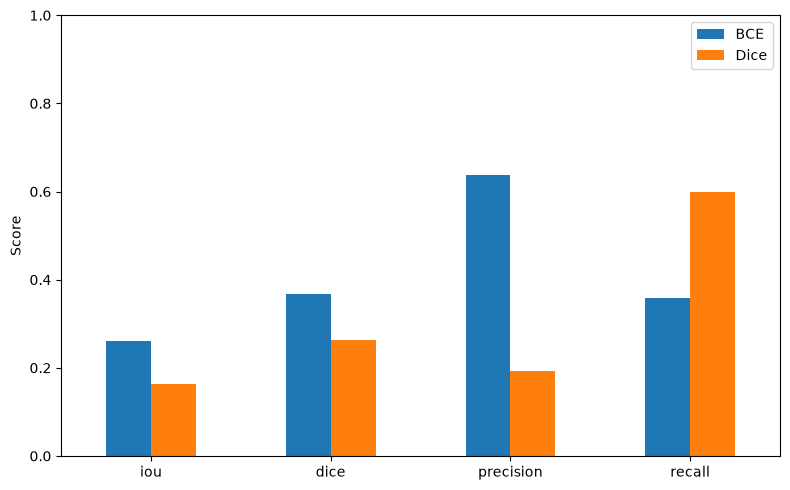

In [ ]:
import pandas as pd


s1 = evaluate_model(unet, test_loader, device)
s2 = evaluate_model(unet2, test_loader, device)


pd.DataFrame({
    "BCE": s1,
    "Dice": s2,
}).plot.bar(rot=0, figsize=(8, 5), ylabel="Score", ylim=(0, 1))

plt.tight_layout()
plt.show()